## Library Imports

In [123]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, PowerNorm, Normalize
import scipy.constants as sc   # mks
from scipy.integrate import trapezoid, cumulative_trapezoid

In [2]:
# graph customization
plt.rcParams['legend.frameon'] = True
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['legend.borderpad'] = 0.3
plt.rcParams['legend.labelspacing'] = 0.3
plt.rcParams['legend.handletextpad'] = 0.3
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'DejaVu Serif'
plt.rcParams['font.weight'] = 'light'
plt.rcParams['font.size'] = 15
plt.rcParams['xtick.top'] = True
plt.rcParams['ytick.right'] = True
plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.minor.visible'] = True
plt.rcParams['xtick.minor.width'] = 2
plt.rcParams["axes.linewidth"] = 1.5

## Physical Parameters for Testing

In [110]:
# constants, in cgs 

au = 1.493e13 # cm
G = 6.67e-8 # gravitational constant, cgs
Msun =  1.989e33 # stellar mass, in g
Mearth = 5.97e27 # earth mass, grams
h = 6.625e-27 # erg*s
k = 1.38e-16 # Boltzmann constant, erg/K
c = 2.998e10 # speed of light, cm/s

mu = 2.3 # for neutral gas 
mH = 1.67e-24 # mass of hydrogen molecule, g

In [4]:
# definition some initial physical parameters for basic testing

p = 1 
r0 = 1 *sc.au * 1e2 # cm
T0 = 200 # K
q = 0.5
Sigma0 = 1e3
Mstar = 1 # AU

In [5]:
# defining r and z grid

r_ = np.logspace(-1, 3, 64) * sc.au * 1e2
z_ = np.logspace(-2, 3, 128) * sc.au * 1e2

r_ = np.linspace(0.1, 100, 64) * sc.au * 1e2
z_ = np.linspace(0.1, 100, 128) * sc.au * 1e2

r, z = np.meshgrid(r_, z_)

## Temperature Profile

In [6]:
# 2D temperature profile 

def temperature(r, z, r0, T0, q):
    return T0 * (r / r0)**-q

temps = temperature(r, z, r0, T0, q)

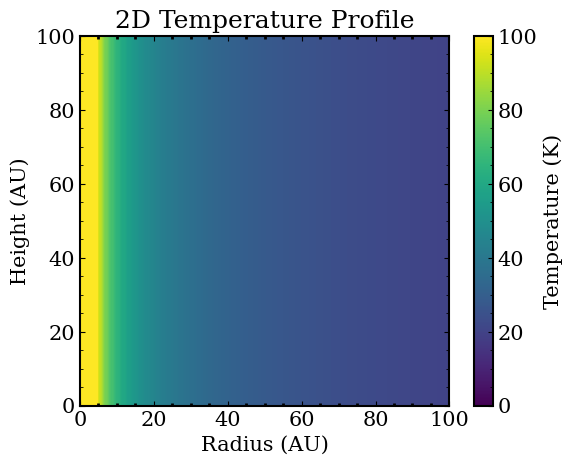

In [7]:
# plot 2d temperature profile

fig, ax = plt.subplots()

ext = (np.min(r_ / (1e2 * sc.au)), np.max(r_ / (1e2 * sc.au)), np.min(z_ / (1e2 * sc.au)), np.max(z_ / (1e2 * sc.au)))
image = ax.imshow(temps, cmap='viridis', extent=ext, origin='lower', norm=Normalize(vmin=0, vmax=100))
ax.set_xlim([0., 100])
ax.set_ylim([0., 100])
ax.set_xlabel('Radius (AU)')
ax.set_ylabel('Height (AU)')
ax.set_title('2D Temperature Profile')
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Temperature (K)")
plt.show()

[[632.45553203 154.04159685 110.57610156 ...  20.32489138  20.16048257
   20.        ]
 [632.45553203 154.04159685 110.57610156 ...  20.32489138  20.16048257
   20.        ]
 [632.45553203 154.04159685 110.57610156 ...  20.32489138  20.16048257
   20.        ]
 ...
 [632.45553203 154.04159685 110.57610156 ...  20.32489138  20.16048257
   20.        ]
 [632.45553203 154.04159685 110.57610156 ...  20.32489138  20.16048257
   20.        ]
 [632.45553203 154.04159685 110.57610156 ...  20.32489138  20.16048257
   20.        ]]


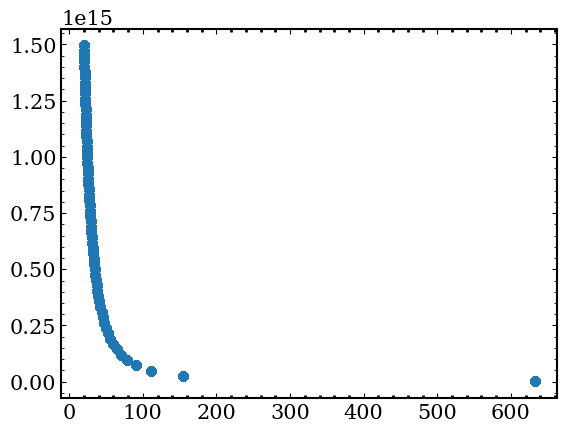

In [8]:
# slice out T(r) profile at some arbitrary z 
z = 200 * sc.au * 1e2
temp_slice = temperature(r, z, r0, T0, q)
print(temp_slice)
plt.scatter(temp_slice, r)
plt.show()

## Velocity Profile

In [7]:
# 2D velocity profile 
def velocity_profile(r, z, Mstar, p, q, T0, r0, mu):
    # azimuthal velocity, assuming vertically hydrostatic protoplanetary disk 
    # p = power-law exponent of the midplane density 
    # q = temperature exponent 
    # T0, temperature at r0 (reference radius, cm)
    # mu = mean molecular weight 

    Mstar_g = Mstar * Msun

    #temperature profile 
    T = temperature(r, z, r0, T0, q)

    # assuming isothermal sound speed 
    cs2 = k * T / (mu * mH)
    cs = np.sqrt(cs2)

    # Keplarian angular frequency at cylindrical radius (r)
    Omega_k = np.sqrt(G * Mstar_g / r**3)

    # Local pressure scale height
    H = cs / Omega_k

    # distance from central star
    spherical_radius = np.sqrt(r**2 + z**2)

    dlnP_dlnr = (
    -(p + q)
    + 0.5 * (3 - q) * (z / H)**2
)

    # radial force balance
    v_phi_squared = (
        G * Mstar_g * r**2 / spherical_radius**3 + cs2 * dlnP_dlnr
    )

    v_phi = np.sqrt(v_phi_squared)

    return v_phi

In [10]:
# random physical parameters 
#r0 = 10 * sc.au * 1e2

v_phi = velocity_profile(r, z, Mstar, p, q, T0, r0, mu)

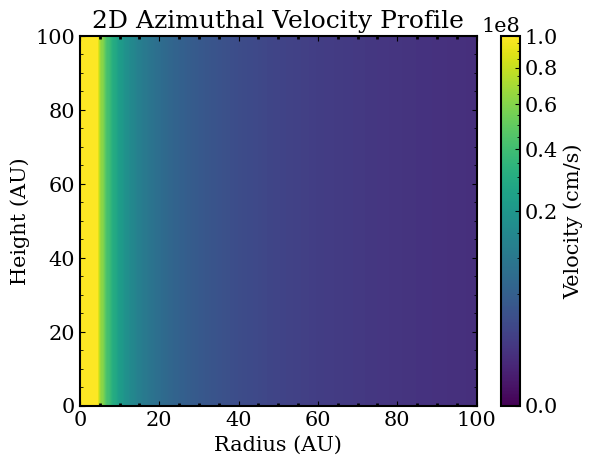

In [11]:
# plot 2d azimuthal velocity profile

fig, ax = plt.subplots()

extent = (
    r_[0] / (sc.au * 1e2),
    r_[-1] / (sc.au * 1e2),
    z_[0] / (sc.au * 1e2),
    z_[-1] / (sc.au * 1e2)
)

ext = (np.min(r_ / (1e2 * sc.au)), np.max(r_ / (1e2 * sc.au)), np.min(z_ / (1e2 * sc.au)), np.max(z_ / (1e2 * sc.au)))
image = ax.imshow(v_phi, cmap='viridis', aspect='auto', extent=extent, origin='lower', norm = PowerNorm(gamma = 0.4, vmin=0, vmax=1e8))
ax.set_xlim([0., 100])
ax.set_ylim([0., 100])
ax.set_xlabel('Radius (AU)')
ax.set_ylabel('Height (AU)')
ax.set_title('2D Azimuthal Velocity Profile')
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Velocity (cm/s)")
plt.show()

In [12]:
# sanity check for velocity profile 

print(velocity_profile(r=1 * sc.au * 1e2, z = 0 * sc.au * 1e2, Mstar = 1, p = 1, q = 0.5, T0 = 30, r0 = r0, mu = mu))

2977679.9087415286


## 2D Surface Density Profile

In [210]:
# 2D surface density profile 

# add outer radius to this function
def Sigma_function(r, r0 = r0, p = p, Sigma0 = Sigma0):
    Sigma = Sigma0 * (r / r0)**(-p) * np.exp(-(r/(100*sc.au*1e2))**2)

    Sigma = np.nan_to_num(Sigma, nan = 0, posinf = 0, neginf = 0)
    #Sigma[r>100 * sc.au * 1e2] = 0
    return Sigma

def H_function(r, z, T0 = 200, Mstar =1, mu=2.3):
    # pressure scale height
    Mstar_g = Mstar * Msun
    T = temperature(r, z, r0=r0, T0=T0, q=q)
    top = r**3 * k * T
    bottom = G * Mstar_g * mu * mH
    H = np.sqrt(top/bottom)

    return H

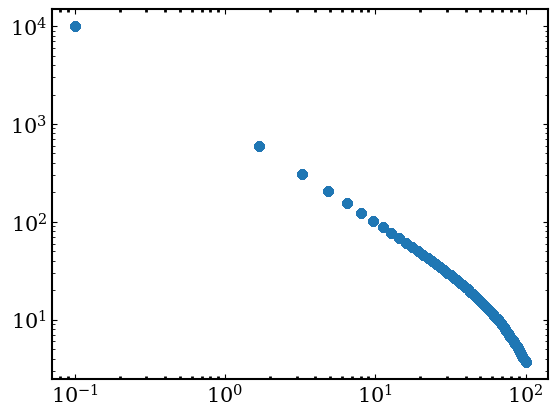

In [211]:
Sigma = Sigma_function(r, r0, p, Sigma0)
fig, ax = plt.subplots()

# ext = (np.min(r_ / (1e2 * sc.au)), np.max(r_ / (1e2 * sc.au)), np.min(z_ / (1e2 * sc.au)), np.max(z_ / (1e2 * sc.au)))
# image = ax.imshow(Sigma, cmap='viridis', extent = ext, origin='lower')
# ax.set_xlim([0., 100])
# ax.set_ylim([0., 100])
# ax.set_xlabel('Radius (AU)')
# ax.set_ylabel('Height (AU)')
# colorbar = fig.colorbar(image, ax=ax)
# colorbar.set_label("Density (g/cm^3)")
# plt.show()

plt.scatter(r/(sc.au * 1e2), Sigma)
plt.xscale('log')
plt.yscale('log')
plt.show()

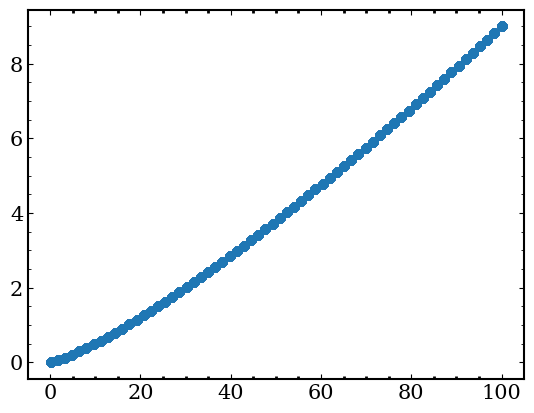

In [15]:
H = H_function(r, z, T0, Mstar, mu)
plt.scatter(r / (sc.au * 1e2), H / (sc.au * 1e2))
plt.show()

In [212]:
# NUMERICALLY solve for density function/structure: should call the temperature profile 
# assume gaussian density distribution

def density_profile(r, z, r0, p, q, Mstar, Sigma0, T0, mu):

    Mstar_g = Mstar * Msun

    # temperature profile
    T = temperature(r, z, r0=r0, T0=T0, q=q)

    # surface mass density 
    Sigma = Sigma_function(r, r0, p, Sigma0)

    H = H_function(r, z, T0, Mstar, mu)

    rho0 = Sigma / (np.sqrt(2 * np.pi) * H)

    rho = rho0 * np.exp(-z**2 / (2 * H**2))

    return rho

/var/folders/v_/k29f_6tn5f9g3ndpvq753fbr0000gn/T/ipykernel_6293/1153728440.py:4: RuntimeWarning: divide by zero encountered in log10
  log_rho = np.nan_to_num(np.log10(rho), nan = -25, neginf = -25, posinf = -10)


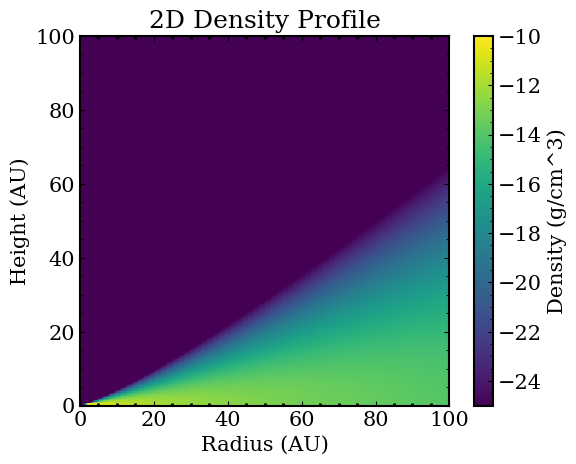

In [213]:
# plot 2d density profile

rho = density_profile(r, z, r0, p, q, Mstar, Sigma0, T0, mu)
log_rho = np.nan_to_num(np.log10(rho), nan = -25, neginf = -25, posinf = -10)

fig, ax = plt.subplots()

ext = (np.min(r_ / (1e2 * sc.au)), np.max(r_ / (1e2 * sc.au)), np.min(z_ / (1e2 * sc.au)), np.max(z_ / (1e2 * sc.au)))
image = ax.imshow(log_rho, cmap='viridis', extent = ext, origin='lower', vmin = -25, vmax = -10)
ax.set_xlim([0., 100])
ax.set_ylim([0., 100])
ax.set_xlabel('Radius (AU)')
ax.set_ylabel('Height (AU)')
ax.set_title('2D Density Profile')
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Density (g/cm^3)")
plt.show()

In [19]:
# play with slicing (for density and temperature)
# pick radius and plot dnsity as a function of z
# 

## Coordinate Transformation Code

In [185]:
# function that generates the sky-frame coordinate grid!
# returns a set of 3, 3D arrays

def sky_frame(start, stop, cell_num):
    # start/stop: starting/stopping value 
    # cell_num: number of desired cells
    
    x_s_ = np.linspace(start, stop, cell_num) 
    y_s_ = np.linspace(start, stop, cell_num)
    z_s_ = np.linspace(start, stop*3, cell_num * 4)

    x_s, y_s, z_s = np.meshgrid(x_s_, y_s_, z_s_, indexing="ij")

    return x_s, y_s, z_s

In [49]:
# function that generates the corresponding disk-frame coordinates

def disk_frame(x_s, y_s, z_s, i, PA):

    # conversion from degree to radians
    i = np.deg2rad(i)
    PA = np.deg2rad(PA)

    # inclination rotation matrix (from sky to disk)
    # M_i = np.array([
    #     [1, 0, 0],
    #     [0, np.cos(i), np.sin(i)],
    #     [0, -np.sin(i), np.cos(i)]
    # ])

    # # position angle rotation matrix 
    # M_PA = np.array([
    #     [np.cos(PA), np.sin(PA), 0],
    #     [-np.sin(PA), np.cos(PA), 0],
    #     [0, 0, 1]
    # ])

    # combined matrix of position angle and inclination:
    Mi_MPA = np.array([
        [np.cos(PA), np.sin(PA), 0],
        [-np.cos(i) * np.sin(PA), np.cos(i)*np.cos(PA), np.sin(i)],
        [np.sin(i)*np.sin(PA), -np.sin(i)*np.cos(PA), np.cos(i)],
    ])


    # transforming sky grid into disk grid (first PA rotation, then inclination angle)
    x_d = Mi_MPA[0,0]*x_s + Mi_MPA[0,1]*y_s + Mi_MPA[0,2]*z_s
    y_d = Mi_MPA[1,0]*x_s + Mi_MPA[1,1]*y_s + Mi_MPA[1,2]*z_s
    z_d = Mi_MPA[2,0]*x_s + Mi_MPA[2,1]*y_s + Mi_MPA[2,2]*z_s

    disk_coordinates = np.stack([x_d, y_d, z_d], axis = 0)
    print(disk_coordinates.shape)
    return disk_coordinates

In [50]:
# calling coordinate functions
i = 45
PA = 0 

x_s, y_s, z_s = sky_frame(-150* sc.au * 1e2, 150* sc.au * 1e2, 80) 
x_d, y_d, z_d = disk_frame(x_s, y_s, z_s, i, PA)

print(np.shape(z_d))

r_d = np.sqrt(x_d**2 + y_d**2)

temps_disk_frame = temperature(r_d, z_d, r0, T0, q)
velocity_disk_frame = velocity_profile(r_d, z_d, Mstar, p, q, T0, r0, mu)

density_disk_frame = density_profile(r_d, z_d, r0, p, q, Mstar, Sigma0, T0, mu)

print(temps_disk_frame.shape)

(3, 80, 80, 80)
(80, 80, 80)
(80, 80, 80)


In [78]:
# at inclination = 0, integrate through the line of sight (z_s), plot it as a function of x_s, y_s to determine morphology (surface density sigma!!!)
# at repeated index values, make sure you get the same value for every value 

# integrating density over line of sight (los), given inclination and sky components
def int_los(x_s, y_s, z_s, i, PA):

    # converting to disk frame
    x_d, y_d, z_d = disk_frame(x_s, y_s, z_s, i, PA)

    r_d = np.sqrt(x_d**2 + y_d**2)

    # generating disk density map
    density_disk_frame = density_profile(np.sqrt(x_d**2 + y_d**2), z_d, r0, p, q, Mstar, Sigma0, T0, mu)

    # integrating over line of sight; axis = -1 tells the function to integrate over the last index (z)
    surface_density = trapezoid(density_disk_frame, x = z_s, axis=-1)
    return surface_density

(3, 170, 170, 680)


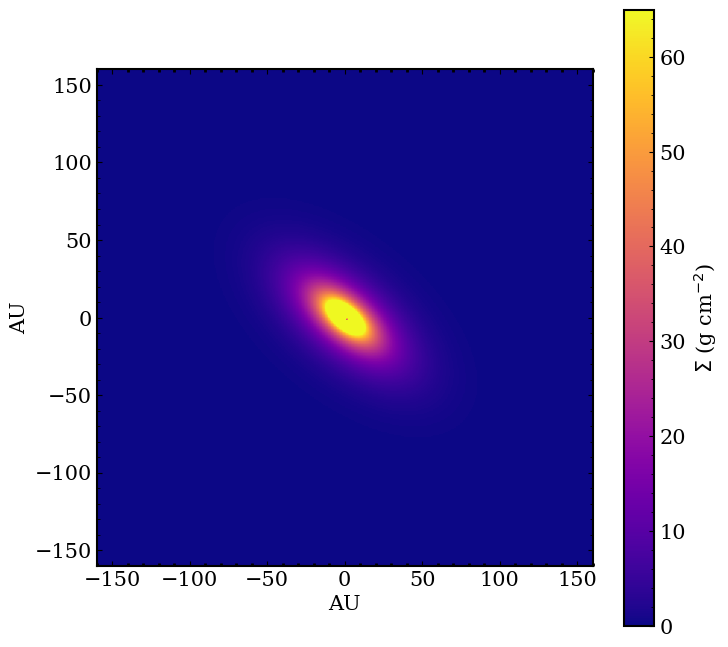

In [220]:
x_s, y_s, z_s = sky_frame(-300* sc.au * 1e2, 300* sc.au * 1e2, 170) 

i = 60
PA = -50

integrating = int_los(x_s, y_s, z_s, i, PA)

vmin = np.min(0.01)
vmax = np.max(integrating)

fig,ax = plt.subplots(figsize=(8,8))
image = ax.imshow(
    integrating,
    origin="lower",
    extent=(-160, 160, -160, 160),
    cmap="plasma",
    vmin = 0,
    vmax = 65
    #norm = PowerNorm(vmin = vmin, vmax = vmax, gamma = 0.5)
)

cbar = fig.colorbar(image, ax=ax)
cbar.set_label(r"$\Sigma$ (g cm$^{-2}$)")
ax.set_xlabel("AU")
ax.set_ylabel("AU")
plt.show()

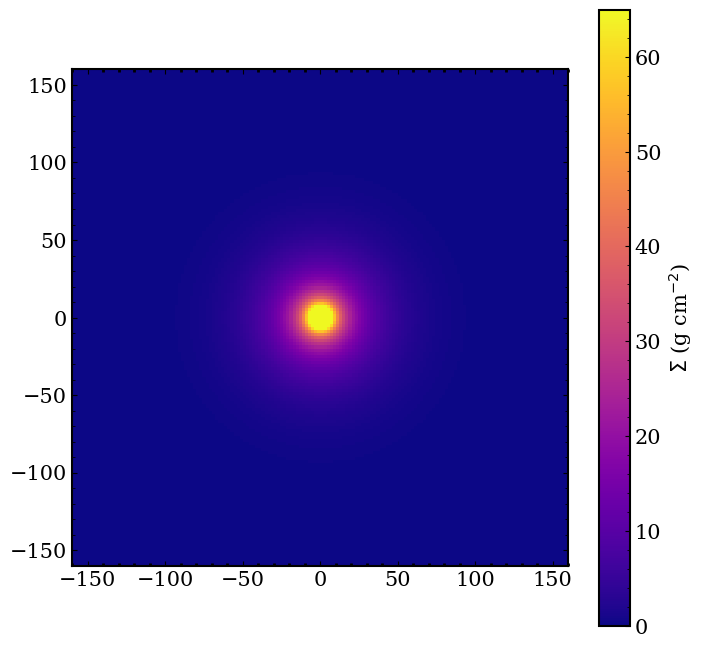

In [221]:
x_d_1d = np.linspace(-300, 300, 160) * sc.au * 1e2
y_d_1d = np.linspace(-300, 300, 160) * sc.au * 1e2

x_d_plane, y_d_plane = np.meshgrid(
    x_d_1d,
    y_d_1d
)

r_d_plane = np.sqrt(x_d_plane**2 + y_d_plane**2)

Sigma_disk = Sigma_function(
    r_d_plane,
    r0,
    p,
    Sigma0
)


fig, ax = plt.subplots(figsize=(8, 8))

image = ax.imshow(
    Sigma_disk,
    origin="lower",
    extent=(-160, 160, -160, 160),
    cmap="plasma",
    vmin = 0,
    vmax = 65
    )


cbar = fig.colorbar(image, ax=ax)
cbar.set_label(r"$\Sigma$ (g cm$^{-2}$)")

## Building Out Model
> Need to strategize... nested functions to avoid continously converting coordinates in every function?
> l is the lower level transition number... I.e J_(3_2), l = 2, etc.
> Make a channel map at a single velocity, and then check for higher/lower velocities
> Z = partition function
> Ask Sean for constants for radiative transfer equations 

In [222]:
# S_nu(s)

def planck_function(T, nu):
    # planck function B_nu(T), T = temperature in K, nu = frequency in Hz
    x = h * nu / (k * T)
    return (2*h*nu**3/c**2) / np.expm1(x)

def source_function(x_s, y_s, z_s, i, PA, r0, T0, q, nu):

    # converting to disk frame
    x_d, y_d, z_d = disk_frame(x_s, y_s, z_s, i, PA)
    r_d = np.sqrt(x_d**2 + y_d**2)
    
    T = temperature(r_d, z_d, r0, T0, q)

    return planck_function(T, nu)

# function for emission functions:
# n (total number of CO molecules at lower transition level)
# K_nu (absorbing coefficient of the circumstellar medium) 
# S (source function, approximated as the Planck equation)
def emission_functions(x_s, y_s, z_s,
                       i, PA,
                       r0, p, q,
                      Mstar, Sigma0, T0, alpha,
                      mu_mean, nu, nu_0,
                      mu_CO):
    # mu_CO is the dipole moment of the CO molecule
    # m_mean = mean molecular weight
    # alpha = Shakura-Sunyaev parameter (turbulence)

    # converting to disk frame
    x_d, y_d, z_d = disk_frame(x_s, y_s, z_s, i, PA)
    r_d = np.sqrt(x_d**2 + y_d**2)
    
    # constants 
    X_CO = 1e-4 # fraction of molecules present in the gas respectively (i.e. CO abundance)
    mass_CO = 28 * mH # mass of CO molecule

    # CO(3-2) transition
    J_l = 2 # lower transition level
    J_u = 3 # upper transition level
    T_1 = 2.766 # K, temperature equivalent to the transition energy 
    g_l = 2 * J_l + 1 # lower-level statistical weight

    # disk density and temp
    rho = density_profile(r_d, z_d, r0, p, q, Mstar, Sigma0, T0, mu_mean) 
    T = temperature(r_d, z_d, r0, T0, q) # temperature of gas 

    # turbulent velocity 
    cs2 = k * T / (mu_mean * mH)
    cs = np.sqrt(cs2) # sound speed
    v_turb = np.sqrt(alpha) * cs # turbulent velocity

    # partition function at the gas temperature 
    Z = np.sqrt(1 + (2*T/T_1)**2) 

    # number density of CO molecules 
    E_l = (1/2) * J_l * (J_l+1)*k*T_1 # energy level
    n_CO = X_CO * rho / mass_CO
    n_l = n_CO * g_l * np.exp(-E_l/(k*T))/Z

    # absorbing cross section
    sigma0_top = 8 * np.pi**3 * k * T_1 * (J_l+1)**2 * mu_CO**2 
    sigma0_bottom = h**2 * c * (2 * J_l + 1)
    sigma0 = sigma0_top/sigma0_bottom # integrated cross section of the transition

    v_phi = velocity_profile(r_d, z_d, Mstar, p, q, T0, r0, mu_mean)
    v_k = v_phi * np.sin(np.deg2rad(i)) * x_d/r_d
    v_obs = (c/nu_0) * (nu - nu_0)  
    delta_v = v_obs - v_k # difference between v_obs and component of gas velocity along the line of sight (v_k)
    delta_V = np.sqrt((2*k*T/mass_CO) + v_turb**2)
    
    phi_nu = (c / nu_0) * 1/(delta_V * np.sqrt(np.pi)) * np.exp(-delta_v**2/delta_V**2) # intrinsic line profile
    sigma_nu = sigma0 * phi_nu * (1 - np.exp((-h * nu)/(k*T)))

    # absorption coefficient K_nu
    K_d = 0 # initially assume that dust absorption is negligible 
    K_mol = n_l * sigma_nu
    K_nu = K_mol + K_d

    S_nu = planck_function(T, nu)
    
    return K_nu, S_nu

                  

In [223]:
# function for optical depth (tau)

# observed emission in each direction between the observer and emitting source 
def intensity(K_nu, S_nu, z_s):
    # we want the intensity along each line of sight 
    tau_cumulative = cumulative_trapezoid(
        K_nu,
        x = z_s,
        axis = -1,
        initial = 0
    )

    tau_total = tau_cumulative[..., -1, np.newaxis]

    tau_to_observer = tau_total - tau_cumulative

    I_integrand = S_nu * K_nu * np.exp(-tau_to_observer)
    I_nu = trapezoid(
        I_integrand, 
        x = z_s,
        axis = -1
    )
    
    return I_nu 

(3, 170, 170, 680)
K_nu shape: (170, 170, 680)
S_nu shape: (170, 170, 680)
I_nu shape: (170, 170)


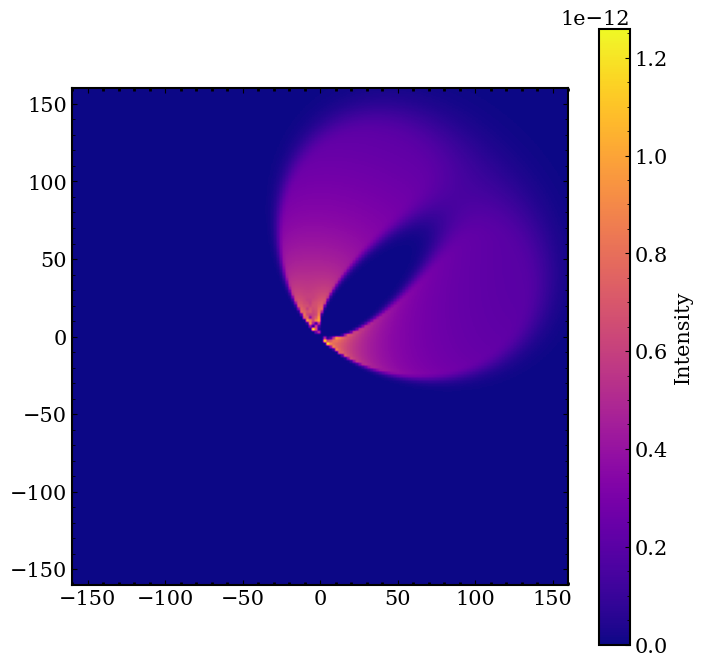

In [224]:
v_channel = 1e5

nu_0 = 345.796e9 # Hz, rest frequency of the molecular transition
mu_mean = 2.37
mu_CO = 1.22e-19 
alpha = 0.5
nu = nu_0 * (1+v_channel/c)
i = 45
PA = 45


K_nu, S_nu = emission_functions(x_s, y_s, z_s,
                       i, PA,
                       r0, p, q,
                      Mstar, Sigma0, T0, alpha,
                      mu_mean, nu, nu_0,
                      mu_CO)

I_nu = intensity(K_nu, S_nu, z_s)


print("K_nu shape:", K_nu.shape)
print("S_nu shape:", S_nu.shape)
print("I_nu shape:", I_nu.shape)


fig, ax = plt.subplots(figsize=(8, 8))

image = ax.imshow(
    I_nu,
    origin="lower",
    extent=(-160, 160, -160, 160),
    cmap="plasma"
)


cbar = fig.colorbar(image, ax=ax)
cbar.set_label("Intensity")

(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)
(3, 170, 170, 680)


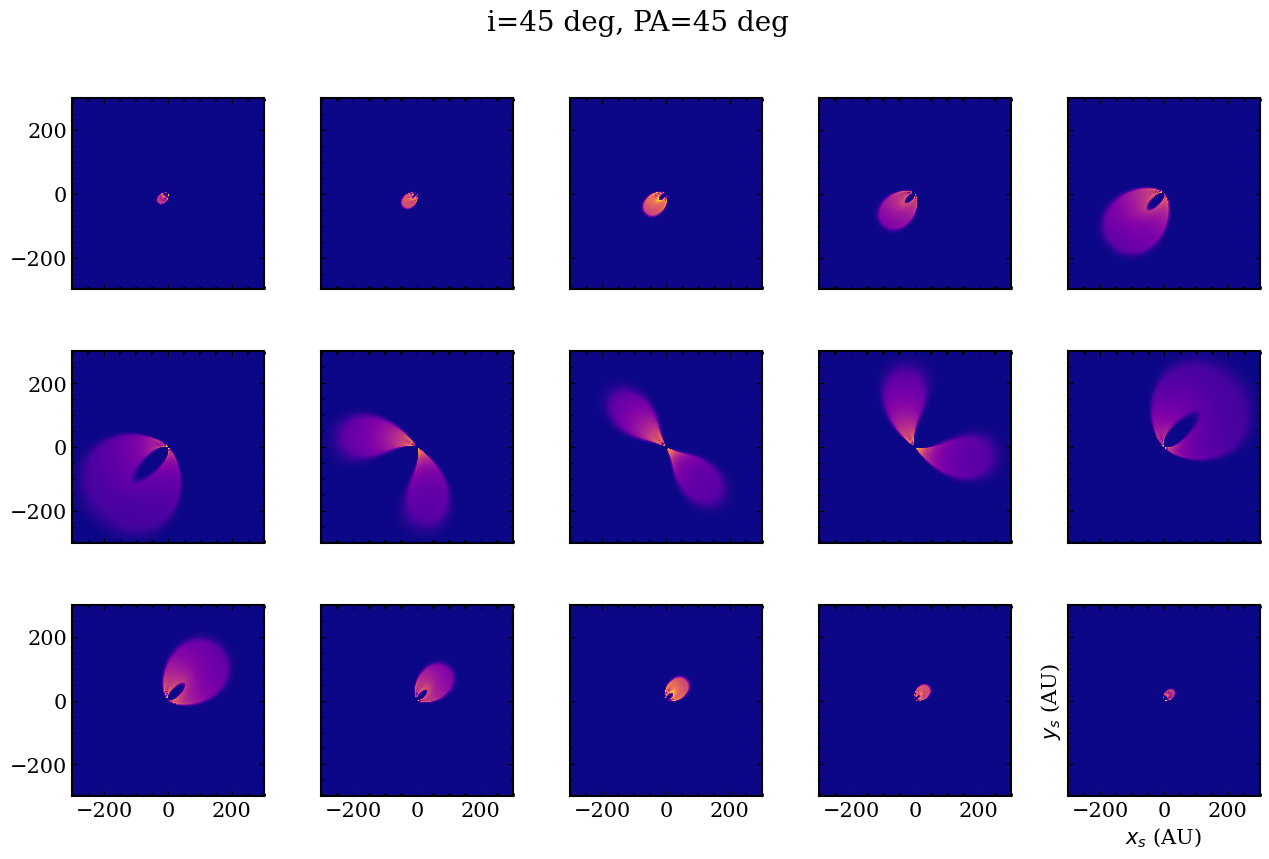

In [231]:
# calculating multiple velocity channels

velocity_channels = np.linspace(-4, 4, 15) * 1e5 # cm/s
intensities = []
i = 45
PA = 45

for v_channel in velocity_channels:
    nu = nu_0 * (1+v_channel/c)

    K_nu, S_nu = emission_functions(x_s, y_s, z_s,
                       i, PA,
                       r0, p, q,
                      Mstar, Sigma0, T0, alpha,
                      mu_mean, nu, nu_0,
                      mu_CO)
    I_channel = intensity(K_nu, S_nu, z_s)

    intensities.append(I_channel)

# plotting channel images
fig, axes = plt.subplots(
    3,5,
    figsize=(13,9),
    sharex=True,
    sharey=True
)


for ax, I_channel, velocity_channel in zip(
    axes.flat,
    intensities,
    velocity_channels
):
    image = ax.imshow(
        I_channel,
        origin="lower",
        extent=(-300, 300, -300, 300),
        cmap="plasma"
    )

fig.suptitle(f"i={i} deg, PA={PA} deg", fontsize=20)
ax.set_xlabel(r"$x_s$ (AU)")
ax.set_ylabel(r"$y_s$ (AU)")

plt.tight_layout()
plt.show()